# 4.3 Búsqueda de hiperparámetros

En esta sección seleccionamos la tasa de aprendizaje, el *weight decay* y el dropout de cada modelo con el mismo espacio, método y presupuesto para los tres. La selección usa solo el conjunto de validación.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src import config as C
from src import plots as P
from src.persist import is_done, load_pickle, save_pickle

P.setup()
C.ensure_dirs()
pd.set_option("display.precision", 4)
print("Resultados:", C.RESULTS.name, "| modelos:", ", ".join(C.MODELS))

Resultados: results | modelos: CNN, MobileNetV2, ResNet-18


In [2]:
RUN_TRAINING = False     # True solo si se quiere entrenar desde aquí; lo recomendado es la terminal

if RUN_TRAINING:
    import subprocess
    # Se lanza como proceso aparte: así el DataLoader con workers funciona en Windows y
    # una corrida interrumpida se reanuda igual que desde la terminal.
    subprocess.run([sys.executable, "-m", "src.runner", "hpo"], cwd=ROOT, check=False)

## Protocolo

| Elemento | Valor (igual para los tres modelos) |
|---|---|
| Método | Búsqueda en malla, $2 \times 2 \times 2 = 8$ configuraciones |
| Espacio | `lr` ∈ {1e-3, 3e-4}; `weight_decay` ∈ {1e-4, 5e-4}; `dropout` ∈ {0.2, 0.4} |
| Valores fijos | AdamW, lote de 32, calentamiento lineal de 3 épocas y decaimiento coseno hasta `lr`·1e-2, precisión mixta, recorte del gradiente a norma 5 |
| Presupuesto | 1 semilla (100, distinta de las del experimento final), máximo 50 épocas, *early stopping* con paciencia de 15 épocas sobre el F1 macro de validación |
| Criterio | Mayor F1 macro de validación; en caso de empate, la configuración de menor índice |

In [3]:
from src.design import hpo_table

tab = hpo_table()
faltan = tab.loc[~tab["done"], ["model", "trial"]]
assert faltan.empty, f"Faltan {len(faltan)} trials. Ejecuta: python -m src.runner hpo"
sel = load_pickle(C.COMMON / "hpo_selected.pkl")

ancha = tab.pivot(index="trial", columns="model", values="val_f1_macro")[C.MODELS]
hp_cols = pd.DataFrame(C.HPO_GRID).loc[ancha.index]
display(pd.concat([hp_cols, ancha.round(4)], axis=1))

,lr,weight_decay,dropout,CNN,MobileNetV2,ResNet-18
0,0.0010,0.0001,0.2,0.7691,0.7938,0.8000
1,0.0010,0.0001,0.4,0.7516,0.7854,0.8036
2,0.0010,0.0005,0.2,0.7693,0.7948,0.8101
3,0.0010,0.0005,0.4,0.7644,0.7988,0.7815
4,0.0003,0.0001,0.2,0.8153,0.7771,0.8320
5,0.0003,0.0001,0.4,0.8055,0.7573,0.8358
6,0.0003,0.0005,0.2,0.8155,0.7817,0.8404
7,0.0003,0.0005,0.4,0.8009,0.7756,0.8513


,trial,lr,weight_decay,dropout,F1 macro val
modelo,,,,,
CNN,6,0.0003,0.0005,0.2,0.8155
MobileNetV2,3,0.0010,0.0005,0.4,0.7988
ResNet-18,7,0.0003,0.0005,0.4,0.8513


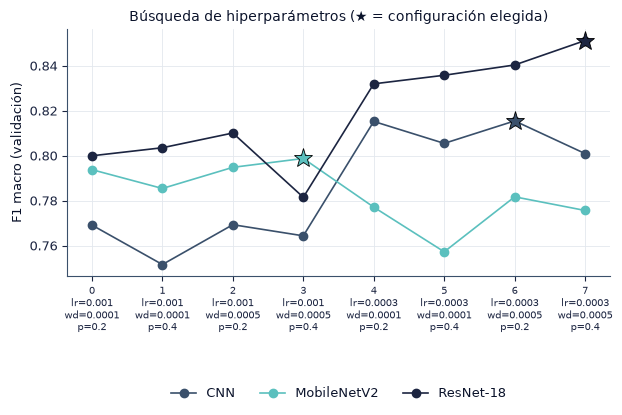

In [4]:
elegidos = pd.DataFrame([{"modelo": m, "trial": v["trial"], "lr": v["hp"]["lr"], "weight_decay": v["hp"]["weight_decay"],
                          "dropout": v["hp"]["dropout"], "F1 macro val": round(v["val_f1_macro"], 4)}
                         for m, v in sel.items()]).set_index("modelo").loc[C.MODELS]
display(elegidos)

fig, ax = plt.subplots(figsize=(7, 3.2))
x = np.arange(len(ancha))
for i, m in enumerate(C.MODELS):
    ax.plot(x, ancha[m], "o-", color=P.color(m), label=m, lw=1.2)
    ax.plot(list(ancha.index).index(sel[m]["trial"]), sel[m]["val_f1_macro"], "*",
            ms=14, color=P.color(m), mec="black", mew=0.6)
ax.set_xticks(x, [f"{t}\nlr={g['lr']:g}\nwd={g['weight_decay']:g}\np={g['dropout']}" for t, g in
                  zip(ancha.index, hp_cols.to_dict("records"))], fontsize=7)
ax.set_ylabel("F1 macro (validación)")
ax.set_title("Búsqueda de hiperparámetros (★ = configuración elegida)")
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.55))
P.save(fig, "4_3_hpo_f1_val", {"tabla": ancha, "elegidos": elegidos})
plt.show()

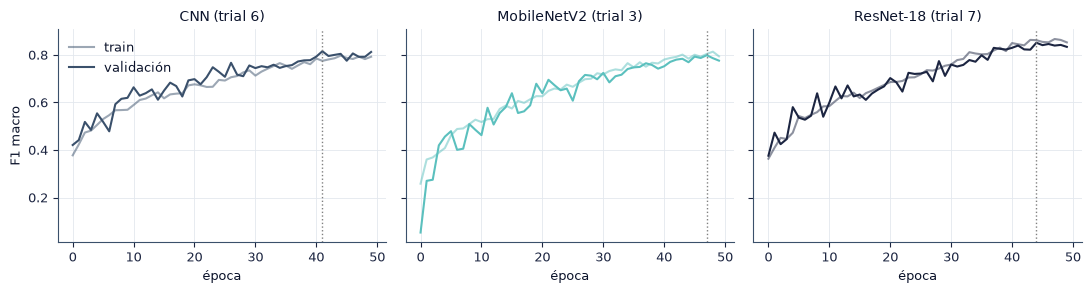

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
curvas = {}
for ax, m in zip(axes, C.MODELS):
    h = load_pickle(C.hpo_dir(m, sel[m]["trial"]) / "history.pkl")
    curvas[m] = h
    ax.plot(h["epoch"], h["train_f1_macro"], color=P.color(m), alpha=0.5, label="train")
    ax.plot(h["epoch"], h["val_f1_macro"], color=P.color(m), label="validación")
    ax.axvline(int(np.argmax(h["val_f1_macro"])), color="grey", ls=":", lw=1)
    ax.set_title(f"{m} (trial {sel[m]['trial']})")
    ax.set_xlabel("época")
axes[0].set_ylabel("F1 macro")
axes[0].legend()
fig.tight_layout()
P.save(fig, "4_3_hpo_curvas_elegidas", curvas)
plt.show()

In [6]:
rango = ancha.max() - ancha.min()
txt = ["**Configuraciones seleccionadas.**"]
for m in C.MODELS:
    v = sel[m]
    txt.append(f"- {m}: trial {v['trial']} (lr = {v['hp']['lr']:g}, weight decay = {v['hp']['weight_decay']:g}, "
               f"dropout = {v['hp']['dropout']}), F1 macro de validación {v['val_f1_macro']:.3f}. "
               f"Rango entre configuraciones: {rango[m]:.3f}.")
display(Markdown("\n".join(txt)))

**Configuraciones seleccionadas.**
- CNN: trial 6 (lr = 0.0003, weight decay = 0.0005, dropout = 0.2), F1 macro de validación 0.815. Rango entre configuraciones: 0.064.
- MobileNetV2: trial 3 (lr = 0.001, weight decay = 0.0005, dropout = 0.4), F1 macro de validación 0.799. Rango entre configuraciones: 0.042.
- ResNet-18: trial 7 (lr = 0.0003, weight decay = 0.0005, dropout = 0.4), F1 macro de validación 0.851. Rango entre configuraciones: 0.070.

## Conclusión

Los tres modelos recibieron el mismo espacio de búsqueda, método y presupuesto. La configuración elegida para cada uno se usa en todas sus corridas finales. Como la selección se hizo con una sola semilla, las diferencias pequeñas entre configuraciones deben compararse con la variación entre semillas estimada en el estudio piloto (sección 4.4).